# 05. Model comparison

**Goal.** Compare Ridge, Random Forest and Gradient Boosting (tuned in notebook 04) with each other and with the baselines, using
**validation data only**, and apply the protocol's rule for whether a complex model replaces Ridge. The outer test groups are not used.

**Removing the tuning advantage.** In notebook 04 each model's settings were picked on the same validation groups they were scored on, which
flatters tuned models against untuned baselines. Here the settings for each held-out validation group are chosen using **only the other
three** validation groups of the same outer fold, then scored on the held-out one. Every number below is therefore free of selection bias
(still only on validation records).

**Also in this notebook.** Seed stability, per-fold results, significance tests, and ablations (feature set, training labels).

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"
sys.path.insert(0, str(Path("training").resolve()))
warnings.filterwarnings("ignore")

import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import wilcoxon
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from common import RESULTS, SEED, SPLITS, environment, group_bootstrap, load, log_run, metrics, paired_diff_bootstrap
from features import FEATURE_SETS, LABEL_SOURCES, add_team_context, feature_matrix, training_set

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 190)
pd.set_option("display.max_columns", 40)
d = add_team_context(load().set_index("record_id", drop=False))
splits = pd.read_csv(SPLITS)
combos = [(t, v, g[["record_id", "role"]]) for (t, v), g in splits.groupby(["outer_test", "inner_val"])]
GOLD = d[d.label_source == "rater"]
tune = pd.read_csv(RESULTS / "tuning_results.csv")
SEEDS = [SEED + i for i in range(5)]
print(environment())
print(len(combos), "combinations;", tune.config_id.nunique(), "tuned settings;", len(SEEDS), "seeds for forest and boosting")

{'python': '3.11.14', 'numpy': '2.4.6', 'pandas': '3.0.6', 'scipy': '1.17.1', 'sklearn': '1.9.1', 'seed': 20261018, 'data_hash': '2a23bdaa674b', 'splits_hash': 'b5793a57b501'}
20 combinations; 345 tuned settings; 5 seeds for forest and boosting


## 1. Selecting the settings without selection bias

For outer fold `o` and held-out validation group `v`: score every setting by its mean MAE over the **other three** validation groups of `o`,
take the best, and then the simplest within one standard error. The chosen setting is refitted on the training groups of combination
`(o, v)` and predicts the rated records of `v`.

In [2]:
def complexity(row):
    p = json.loads(row.params)
    label_rank = LABEL_SOURCES.index(row.label_source) + (0.5 if row.weight != 1.0 else 0)
    if row.model == "Ridge":
        return (label_rank, -p["alpha"])
    if row.model == "Random Forest":
        return (label_rank, p["n_estimators"] * (p["max_depth"] or 10))
    return (label_rank, p["max_iter"] * (p["max_depth"] or 6) * p["learning_rate"] + (0 if p["monotonic"] else 0.001))


def choose(model, fs, outer, held):
    g = tune[(tune.model == model) & (tune.feature_set == fs) & (tune.outer_test == outer) & (tune.inner_val != held)]
    s = (g.groupby("config_id").agg(MAE=("MAE", "mean"), SE=("MAE", lambda x: x.std(ddof=1) / np.sqrt(len(x))), label_source=("label_source", "first"),
                                    weight=("weight", "first"), params=("params", "first"), model=("model", "first")).reset_index())
    best = s.loc[s.MAE.idxmin()]
    near = s[s.MAE <= best.MAE + best.SE].copy()
    near["c"] = near.apply(complexity, axis=1)
    return near.sort_values("c").iloc[0]


pick = choose("Random Forest", "3 features (chosen)", "A", "B")
print("example, outer A, held-out validation group B, forest on 3 features:", pick.label_source, pick.weight, pick.params)

example, outer A, held-out validation group B, forest on 3 features: rated + propagated (real) 1.0 {"n_estimators": 100, "min_samples_leaf": 2, "max_features": 0.5, "max_depth": 4}


In [3]:
def make_model(name, p, n_features, seed):
    if name == "Ridge":
        return make_pipeline(StandardScaler(), Ridge(alpha=p["alpha"]))
    if name == "Random Forest":
        return RandomForestRegressor(random_state=seed, n_jobs=1, **p)
    q = {k: v for k, v in p.items() if k != "monotonic"}
    return HistGradientBoostingRegressor(random_state=seed, early_stopping=False, monotonic_cst=[1] * n_features if p["monotonic"] else None, **q)


def fit(model, name, X, y, w):
    model.fit(X, y, **({"ridge__sample_weight": w} if name == "Ridge" else {"sample_weight": w}))
    return model


_cache = {}


def get_data(ci, fs, kind, label_source, weight):
    key = (ci, fs, kind, label_source, weight)
    if key not in _cache:
        test, val, roles = combos[ci]
        feat = lambda f: feature_matrix(f, fs, kind)  # noqa: E731
        X, y, w, ids = training_set(d, roles, feat, label_source, weight, real_only=False)
        v = d.loc[[i for i in roles[roles.role == "val"].record_id if i in GOLD.index]]
        _cache[key] = (X, y, w, feat(v), v.rater_effort.to_numpy(), v.E_CC.to_numpy(), v.record_id.to_numpy(), v.group.to_numpy())
    return _cache[key]


rows, start = [], time.time()
for model in ("Ridge", "Random Forest", "Gradient Boosting"):
    kind = "linear" if model == "Ridge" else "tree"
    for fs in FEATURE_SETS:
        for ci, (test, val, roles) in enumerate(combos):
            pk = choose(model, fs, test, val)
            X, y, w, Xv, yv, act, rid, grp = get_data(ci, fs, kind, pk.label_source, pk.weight)
            for seed in (SEEDS if model != "Ridge" else SEEDS[:1]):
                m = fit(make_model(model, json.loads(pk.params), X.shape[1], seed), model, X, y, w)
                p = np.clip(m.predict(Xv), 0, 1)
                rows += [(f"{model} | {fs}", model, fs, test, val, seed, r, g, yy, pp, a, pk.label_source, pk.weight)
                         for r, g, yy, pp, a in zip(rid, grp, yv, p, act)]
    print(f"{model}: {time.time() - start:.0f}s")
tuned = pd.DataFrame(rows, columns=["name", "model", "feature_set", "outer_test", "inner_val", "seed", "record_id", "group", "y", "pred", "E_CC", "label_source", "weight"])
tuned.to_csv(RESULTS / "comparison_tuned_predictions.csv", index=False)
print(len(tuned), "predictions")

Ridge: 4s


Random Forest: 110s


Gradient Boosting: 153s
2640 predictions


## 2. Predictions from every model, side by side

Tuned models use the average over seeds for the main numbers. Baselines come from notebook 02 (untuned, except that Ridge there chose
`alpha` by leave-one-out).

In [4]:
base = pd.read_csv(RESULTS / "baseline_validation_predictions.csv")
KEEP = ["mean", "commits (normalised)", "commits (linear)", "commits (linear) + zero rule", "tasks (linear)", "ridge (5 features)"]
base = base[base.model.isin(KEEP)].rename(columns={"model": "name", "E_CC": "E_CC"}).assign(model="baseline", feature_set="", seed=0)

avg = (tuned.groupby(["name", "model", "feature_set", "outer_test", "inner_val", "record_id", "group"])
       .agg(y=("y", "first"), pred=("pred", "mean"), E_CC=("E_CC", "first")).reset_index().assign(seed=0))
allp = pd.concat([avg, base[["name", "model", "feature_set", "outer_test", "inner_val", "record_id", "group", "y", "pred", "E_CC", "seed"]]], ignore_index=True)
print(allp.groupby("name").size().to_string())

name
Gradient Boosting | 3 features (chosen)       80
Gradient Boosting | 5 features (proposal)     80
Gradient Boosting | 5 features, review n/a    80
Random Forest | 3 features (chosen)           80
Random Forest | 5 features (proposal)         80
Random Forest | 5 features, review n/a        80
Ridge | 3 features (chosen)                   80
Ridge | 5 features (proposal)                 80
Ridge | 5 features, review n/a                80
commits (linear)                              80
commits (linear) + zero rule                  80
commits (normalised)                          80
mean                                          80
ridge (5 features)                            80
tasks (linear)                                80


## 3. Results (validation, pooled over 20 combinations; intervals resample whole groups)

In [5]:
table = []
for name, g in allp.groupby("name"):
    m = metrics(g.y, g.pred)
    lo, hi = group_bootstrap(g.y.to_numpy(), g.pred.to_numpy(), g.group.to_numpy(), lambda y, p: np.mean(np.abs(p - y)), n=1000)
    a = g[g.E_CC > 0]
    table.append({"model": name, "MAE": m["MAE"], "MAE 95% CI": f"{lo:.3f}-{hi:.3f}", "RMSE": m["RMSE"], "bias": m["bias"], "Pearson": m["pearson"],
                  "Spearman": m["spearman"], "R2": m["R2"], "CCC": m["CCC"], "calib slope": m["calib_slope"], "band exact": m["band_exact"],
                  "band within 1": m["band_within_1"], "MAE active": float(np.abs(a.pred - a.y).mean())})
results = pd.DataFrame(table).set_index("model").sort_values("MAE")
results.round(3)

,MAE,MAE 95% CI,RMSE,bias,Pearson,Spearman,R2,CCC,calib slope,band exact,band within 1,MAE active
model,,,,,,,,,,,,
commits (normalised),0.053,0.023-0.070,0.072,-0.019,0.962,0.947,0.917,0.955,1.050,0.625,1.000,0.062
commits (linear) + zero rule,0.057,0.031-0.079,0.079,-0.002,0.949,0.924,0.900,0.947,1.001,0.625,1.000,0.068
commits (linear),0.061,0.037-0.081,0.080,0.001,0.947,0.922,0.897,0.945,1.021,0.625,1.000,0.068
Gradient Boosting | 3 features (chosen),0.070,0.049-0.091,0.091,0.009,0.932,0.891,0.867,0.930,0.988,0.588,1.000,0.075
ridge (5 features),0.073,0.043-0.097,0.108,-0.002,0.905,0.874,0.813,0.905,0.922,0.650,0.988,0.086
"Random Forest | 5 features, review n/a",0.075,0.045-0.107,0.106,0.014,0.908,0.908,0.820,0.900,1.020,0.638,0.988,0.080
"Gradient Boosting | 5 features, review n/a",0.075,0.057-0.094,0.099,0.023,0.922,0.874,0.841,0.912,1.037,0.525,1.000,0.081
Gradient Boosting | 5 features (proposal),0.077,0.059-0.098,0.105,0.019,0.910,0.868,0.821,0.902,1.007,0.550,1.000,0.082
Ridge | 3 features (chosen),0.077,0.046-0.094,0.106,-0.005,0.911,0.879,0.818,0.889,1.139,0.562,1.000,0.089


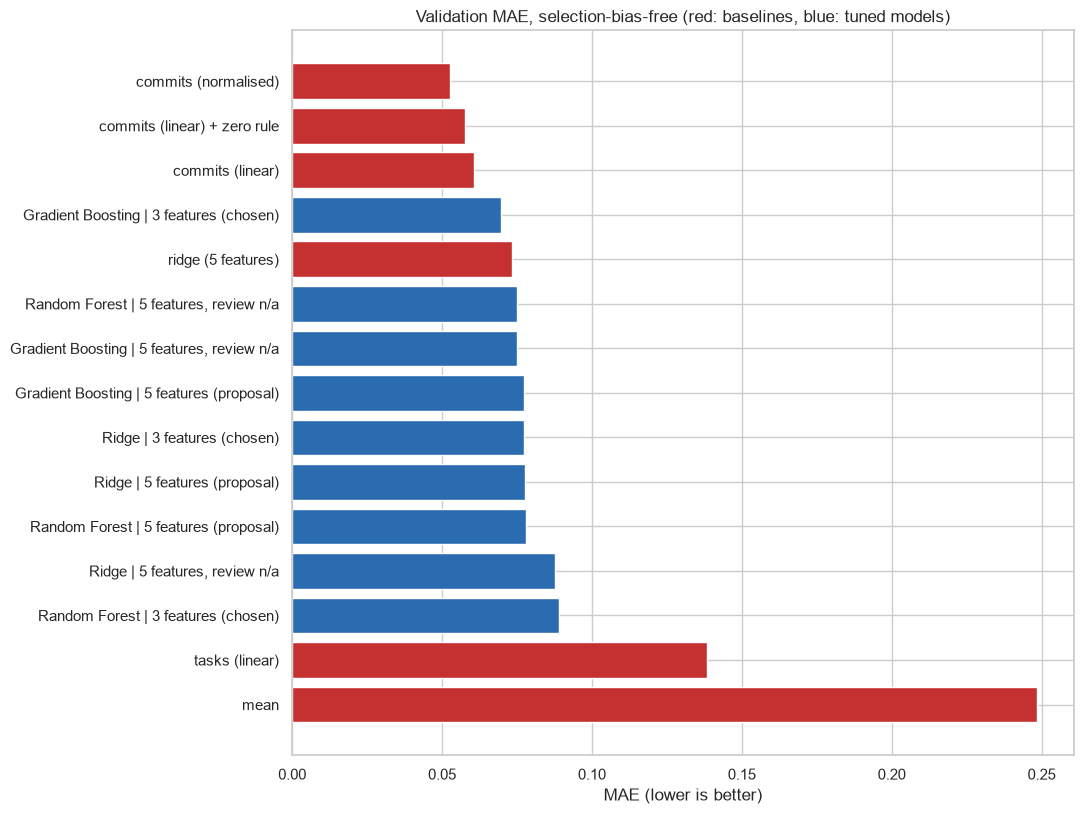

In [6]:
fig, ax = plt.subplots(figsize=(11, 0.42 * len(results) + 2))
colors = ["#c53030" if i.startswith(("mean", "commits", "tasks", "ridge (")) else "#2b6cb0" for i in results.index]
ax.barh(results.index, results.MAE, color=colors)
ax.invert_yaxis()
ax.set(title="Validation MAE, selection-bias-free (red: baselines, blue: tuned models)", xlabel="MAE (lower is better)")
plt.tight_layout()
plt.show()

## 4. Seed stability (forest and boosting)

Different random seeds give different forests and boosted models. How much does the error move?

In [7]:
seed_mae = (tuned[tuned.model != "Ridge"].assign(err=lambda x: (x.pred - x.y).abs()).groupby(["name", "seed"]).err.mean().unstack("seed"))
seed_mae["mean"], seed_mae["std over seeds"], seed_mae["min"], seed_mae["max"] = seed_mae.mean(axis=1), seed_mae.std(axis=1), seed_mae.min(axis=1), seed_mae.max(axis=1)
seed_mae.round(4)

seed,20261018,20261019,20261020,20261021,20261022,mean,std over seeds,min,max
name,,,,,,,,,
Gradient Boosting | 3 features (chosen),0.0698,0.0698,0.0698,0.0698,0.0698,0.0698,0.0000,0.0698,0.0698
Gradient Boosting | 5 features (proposal),0.0772,0.0772,0.0772,0.0772,0.0772,0.0772,0.0000,0.0772,0.0772
"Gradient Boosting | 5 features, review n/a",0.0750,0.0750,0.0750,0.0750,0.0750,0.0750,0.0000,0.0750,0.0750
Random Forest | 3 features (chosen),0.0889,0.0893,0.0873,0.0907,0.0890,0.0891,0.0012,0.0873,0.0907
Random Forest | 5 features (proposal),0.0760,0.0788,0.0786,0.0799,0.0774,0.0781,0.0015,0.0760,0.0799
"Random Forest | 5 features, review n/a",0.0750,0.0762,0.0748,0.0756,0.0739,0.0751,0.0008,0.0739,0.0762


## 5. Per-fold results

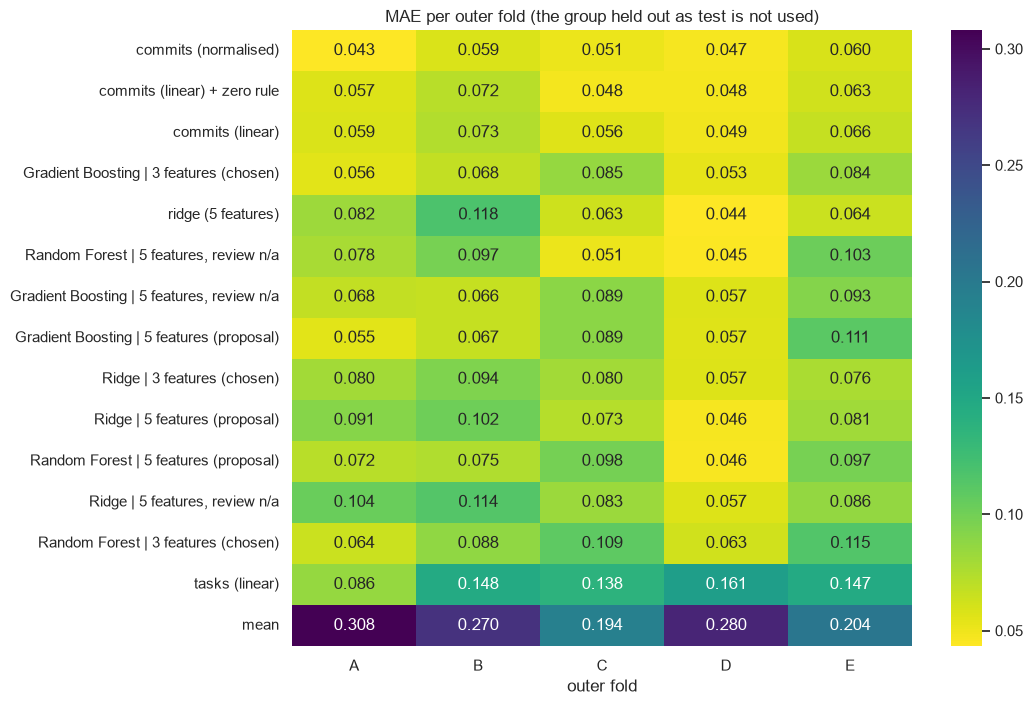

outer_test,A,B,C,D,E,mean,std over folds
model,,,,,,,
commits (normalised),0.043,0.059,0.051,0.047,0.060,0.052,0.007
commits (linear) + zero rule,0.057,0.072,0.048,0.048,0.063,0.057,0.010
commits (linear),0.059,0.073,0.056,0.049,0.066,0.061,0.010
Gradient Boosting | 3 features (chosen),0.056,0.068,0.085,0.053,0.084,0.069,0.015
ridge (5 features),0.082,0.118,0.063,0.044,0.064,0.074,0.028
"Random Forest | 5 features, review n/a",0.078,0.097,0.051,0.045,0.103,0.075,0.026
"Gradient Boosting | 5 features, review n/a",0.068,0.066,0.089,0.057,0.093,0.074,0.015
Gradient Boosting | 5 features (proposal),0.055,0.067,0.089,0.057,0.111,0.076,0.024
Ridge | 3 features (chosen),0.080,0.094,0.080,0.057,0.076,0.078,0.013


In [8]:
fold = (allp.assign(err=lambda x: (x.pred - x.y).abs()).groupby(["name", "outer_test"]).err.mean().unstack("outer_test"))
fold["mean"], fold["std over folds"] = fold.mean(axis=1), fold.std(axis=1)
fig, ax = plt.subplots(figsize=(10, 0.4 * len(fold) + 2))
sns.heatmap(fold.drop(columns=["mean", "std over folds"]).loc[results.index], annot=True, fmt=".3f", cmap="viridis_r", ax=ax)
ax.set(title="MAE per outer fold (the group held out as test is not used)", xlabel="outer fold", ylabel="")
plt.show()
fold.loc[results.index].round(3)

## 6. Is a complex model better than Ridge? The protocol's rule

A forest or boosting model replaces Ridge only if **all** hold, comparing with Ridge on the **same feature set**:

1. MAE at least **0.01** lower than Ridge's (pooled).
2. The 95% group-bootstrap interval of the MAE difference (Ridge minus model) **excludes 0**.
3. Better in at least **4 of the 5** outer folds.
4. It passes the invariants (tested in notebook 07; shown as pending here).

In [9]:
def get(name):
    return allp[allp.name == name].sort_values(["outer_test", "inner_val", "record_id"]).reset_index(drop=True)

decision = []
for fs in FEATURE_SETS:
    ridge = get(f"Ridge | {fs}")
    for model in ("Random Forest", "Gradient Boosting"):
        other = get(f"{model} | {fs}")
        diff = float(np.abs(ridge.pred - ridge.y).mean() - np.abs(other.pred - other.y).mean())
        lo, hi = paired_diff_bootstrap(ridge.y.to_numpy(), ridge.pred.to_numpy(), other.pred.to_numpy(), ridge.group.to_numpy(), n=2000)
        wins = int(sum(np.abs(other[other.outer_test == o].pred - other[other.outer_test == o].y).mean() < np.abs(ridge[ridge.outer_test == o].pred - ridge[ridge.outer_test == o].y).mean()
                       for o in ridge.outer_test.unique()))
        decision.append({"feature set": fs, "model": model, "Ridge MAE": float(np.abs(ridge.pred - ridge.y).mean()), "model MAE": float(np.abs(other.pred - other.y).mean()),
                         "gain (Ridge - model)": diff, "95% CI of gain": f"{lo:.3f} to {hi:.3f}", "folds won (of 5)": wins,
                         "gain >= 0.01": diff >= 0.01, "CI excludes 0": lo > 0, "wins >= 4 folds": wins >= 4,
                         "passes 1-3": (diff >= 0.01) and (lo > 0) and (wins >= 4)})
decision = pd.DataFrame(decision)
decision.round(3)

,feature set,model,Ridge MAE,model MAE,gain (Ridge - model),95% CI of gain,folds won (of 5),gain >= 0.01,CI excludes 0,wins >= 4 folds,passes 1-3
0,5 features (proposal),Random Forest,0.078,0.078,-0.000,-0.044 to 0.031,3,False,False,False,False
1,5 features (proposal),Gradient Boosting,0.078,0.077,0.001,-0.022 to 0.024,2,False,False,False,False
2,"5 features, review n/a",Random Forest,0.088,0.075,0.013,-0.006 to 0.034,4,True,False,True,False
3,"5 features, review n/a",Gradient Boosting,0.088,0.075,0.013,-0.007 to 0.031,3,True,False,False,False
4,3 features (chosen),Random Forest,0.077,0.089,-0.011,-0.060 to 0.017,2,False,False,False,False
5,3 features (chosen),Gradient Boosting,0.077,0.070,0.008,-0.027 to 0.027,3,False,False,False,False


## 7. Against the best simple baseline (commit count alone)

In [10]:
ref = get("commits (normalised)")
vs = []
for name in results.index:
    if name.startswith(("mean", "commits", "tasks")):
        continue
    other = get(name)
    if len(other) != len(ref):
        continue
    lo, hi = paired_diff_bootstrap(ref.y.to_numpy(), ref.pred.to_numpy(), other.pred.to_numpy(), ref.group.to_numpy(), n=2000)
    vs.append({"model": name, "MAE": float(np.abs(other.pred - other.y).mean()), "commits-normalised MAE": float(np.abs(ref.pred - ref.y).mean()),
               "gain over commits": float(np.abs(ref.pred - ref.y).mean() - np.abs(other.pred - other.y).mean()), "95% CI of gain": f"{lo:.3f} to {hi:.3f}",
               "interval excludes 0": lo > 0})
pd.DataFrame(vs).set_index("model").round(3).sort_values("gain over commits", ascending=False)

,MAE,commits-normalised MAE,gain over commits,95% CI of gain,interval excludes 0
model,,,,,
Gradient Boosting | 3 features (chosen),0.070,0.053,-0.017,-0.035 to -0.006,False
ridge (5 features),0.073,0.053,-0.021,-0.037 to -0.004,False
"Random Forest | 5 features, review n/a",0.075,0.053,-0.022,-0.051 to -0.004,False
"Gradient Boosting | 5 features, review n/a",0.075,0.053,-0.022,-0.037 to -0.012,False
Gradient Boosting | 5 features (proposal),0.077,0.053,-0.025,-0.037 to -0.013,False
Ridge | 3 features (chosen),0.077,0.053,-0.025,-0.050 to 0.001,False
Ridge | 5 features (proposal),0.078,0.053,-0.025,-0.058 to -0.008,False
Random Forest | 5 features (proposal),0.078,0.053,-0.025,-0.063 to -0.000,False
"Ridge | 5 features, review n/a",0.088,0.053,-0.035,-0.060 to -0.013,False


## 8. Ablations

What the search says about *which choices* matter, from every setting tried in notebook 04 (mean validation MAE over all settings of a
kind; lower is better).

In [11]:
by_label = tune.groupby(["model", "label_source"]).MAE.mean().unstack("label_source")[LABEL_SOURCES]
by_fs = tune.groupby(["model", "feature_set"]).MAE.mean().unstack("feature_set")
print("by training labels:"); print(by_label.round(4).to_string())
print(); print("by feature set:"); print(by_fs.round(4).to_string())

by training labels:
label_source       rated only  rated + propagated (real)  rated + propagated (real + synthetic)
model                                                                                          
Gradient Boosting      0.1784                     0.0668                                 0.0642
Random Forest          0.1159                     0.0546                                 0.0585
Ridge                  0.1158                     0.0911                                 0.0810

by feature set:
feature_set        3 features (chosen)  5 features (proposal)  5 features, review n/a
model                                                                                
Gradient Boosting               0.0852                 0.0836                  0.0837
Random Forest                   0.0670                 0.0657                  0.0672
Ridge                           0.0898                 0.0924                  0.0939


## 9. Predicted vs rated, and where the models fail

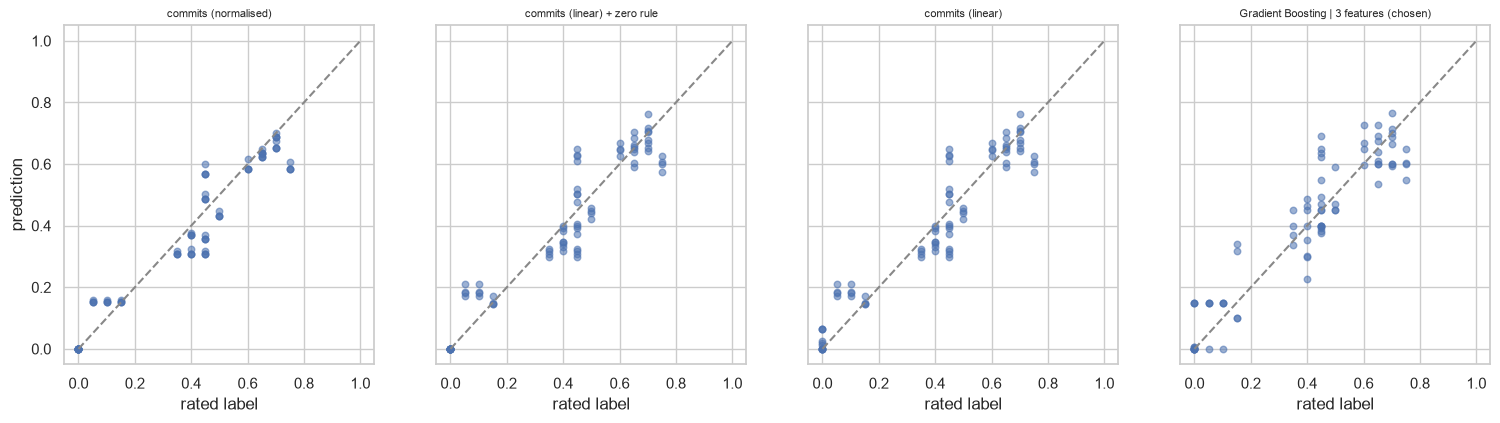

,y,pred,commits,err
record_id,,,,
T13-S2-STU-006,0.75,0.589,13,0.161
T01-S1-STU-009,0.45,0.309,3,0.141
T08-S1-STU-008,0.45,0.575,12,0.125
T04-S3-STU-010,0.05,0.155,1,0.105
T05-S1-STU-012,0.45,0.359,4,0.091
T08-S2-STU-025,0.40,0.311,3,0.089


In [12]:
top = [n for n in results.index if not n.startswith(("mean", "tasks"))][:4]
fig, axes = plt.subplots(1, len(top), figsize=(4.6 * len(top), 4.4), sharex=True, sharey=True)
for a, n in zip(axes, top):
    g = allp[allp.name == n]
    a.scatter(g.y, g.pred, s=22, alpha=.55)
    a.plot([0, 1], [0, 1], "--", color="#888")
    a.set(title=n, xlabel="rated label")
    a.title.set_fontsize(8)
axes[0].set_ylabel("prediction")
plt.show()
worst = allp[allp.name == results.index[0]].assign(err=lambda x: (x.pred - x.y).abs()).groupby("record_id").agg(y=("y", "first"), pred=("pred", "mean"), commits=("E_CC", "first"), err=("err", "mean")).sort_values("err", ascending=False)
worst.head(6).round(3)

## 10. Choose the model for the final test, and log

In [13]:
passing = decision[decision["passes 1-3"]]
if len(passing):
    pick = passing.sort_values("gain (Ridge - model)", ascending=False).iloc[0]
    outcome = {"model": pick["model"], "feature_set": pick["feature set"], "reason": "passes protocol conditions 1-3 against Ridge on the same feature set (invariants pending, notebook 07)"}
else:
    ridge_rows = results[results.index.str.startswith("Ridge |")]
    outcome = {"model": "Ridge", "feature_set": ridge_rows.index[0].split(" | ")[1], "reason": "no forest or boosting model passes protocol conditions 1-3 against Ridge"}
outcome["validation_MAE"] = round(float(results.loc[f"{outcome['model']} | {outcome['feature_set']}"].MAE), 4)
(RESULTS / "model_choice.json").write_text(json.dumps(outcome, indent=2))
for name, row in results.iterrows():
    log_run("05_model_comparison", name, "validation, selection-bias-free, pooled over 20 combinations",
            {"MAE": round(row.MAE, 4), "RMSE": round(row.RMSE, 4), "pearson": round(row.Pearson, 4), "spearman": round(row.Spearman, 4),
             "bias": round(row.bias, 4), "MAE_active": round(row["MAE active"], 4)})
print(json.dumps(outcome, indent=2))

{
  "model": "Ridge",
  "feature_set": "3 features (chosen)",
  "reason": "no forest or boosting model passes protocol conditions 1-3 against Ridge",
  "validation_MAE": 0.0774
}


## 11. Reading the results

**Headline.** With the tuning advantage removed, **no tuned model beats commit count alone**, and none beats Ridge by the protocol's standard.
This is the main result of the Effort experiments so far.

| | MAE (validation, selection-bias-free) |
|---|---|
| commits (normalised, no fitting) | **0.053** |
| commits (linear, + zero rule) | 0.057 |
| commits (linear) | 0.061 |
| Gradient Boosting, 3 features | 0.070 |
| Ridge, 5 features (untuned, notebook 02) | 0.073 |
| Random Forest, 5 features (review n/a) | 0.075 |
| Ridge, 3 features (tuned) | 0.077 |
| Random Forest, 5 features (proposal) | 0.078 |
| Random Forest, 3 features | 0.089 |
| tasks done alone | 0.138 |
| always predict the mean | 0.248 |

**1. The notebook-04 gains were selection.** There, the forest on three features looked best at 0.051; scored without selection bias it is
0.089, and boosting moves from 0.058 to 0.070. Picking the best of ~100 settings on the same four validation groups flattered every tuned
model, as the gap between the median and best setting suggested.

**2. Complex models do not beat Ridge (protocol rule).** Against Ridge on the same feature set, the gain is between -0.011 and +0.013, every
95% interval contains 0, and only one model (the forest with reviews marked n/a) wins 4 of 5 folds. **No model meets conditions 1-3**, so the
protocol's answer is **Ridge**. The model saved for the final test is Ridge on the three chosen features (validation MAE 0.077).

**3. Nothing beats commit count.** The interval of the gain over commits-normalised is negative for every tuned model (the best, boosting on
three features, has gain -0.017, interval -0.035 to -0.006). Why? Commit-normalised has **no fitted parameters**; every other model must
estimate its parameters from 9-15 rated records per fold. At this label count, estimating anything costs more than the extra features add.

**4. Seeds hardly matter.** The forest's error moves by about 0.001-0.0015 across five seeds. Boosting here is deterministic (no subsampling),
so its seeds give identical results. Differences between models are far larger than seed noise.

**5. Per fold.** Commits-normalised is best or near best in every fold and has the smallest spread (0.007). The fitted models vary much more
across folds (spread 0.013-0.028), meaning they depend heavily on which groups are in training.

**6. Ablations (means over all settings tried; includes poor settings).** Propagated labels cut the forest's error from 0.116 to about 0.055
and boosting's from 0.178 to 0.064-0.067: tree models need many rows and cannot learn from 9-15. For Ridge, propagated labels help only the
mean over all settings (0.116 -> 0.081-0.091), because very large `alpha` settings are bad with few rows; its best settings use rated labels
only. The feature set matters little for any model (differences of 0.001-0.003).

**7. Where models fail.** The largest errors are for records near the edges of what the labels cover (e.g. rated 0.75 with 13 commits,
predicted 0.59), and for very small teams' members whose label is below what their few commits suggest.

**What this means.**
- On this dataset, effort as labelled is almost a function of commit volume, and the simplest parameter-free rule reproduces the ratings to
  within about 0.05.
- The proposal's extra features (lines, files, tasks, reviews) and non-linear models cannot be shown to help with 20 rated records. That is a
  statement about the **data size and labels**, not proof the features are useless.
- More rated records, especially high-effort ones, and a rubric that separates work *quality* from volume, are what would let a richer model
  show an advantage. The learning curves in notebook 04 were still falling at 100% of the data.

Saved: `training/results/model_choice.json`, `comparison_tuned_predictions.csv`. Next: **06. Error analysis**, then robustness tests and the
final test.